# Visualización · Matplotlib

Diagramas de líneas, barras, cajas, sectores y áreas con `matplotlib` y `pandas`.

## 1. Evolución de ventas

Pedir las ventas de un rango de años y dibujar un diagrama de líneas con su evolución.

Año inicial: 2020
Año final: 2024
Ventas de 2020: 1200
Ventas de 2021: 1800
Ventas de 2022: 1500
Ventas de 2023: 2100
Ventas de 2024: 2600


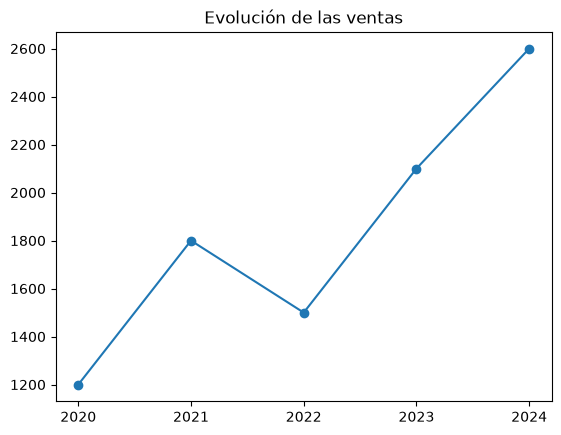

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

inicio, fin = int(input("Año inicial: ")), int(input("Año final: "))
ventas = {año: float(input(f"Ventas de {año}: ")) for año in range(inicio, fin + 1)}
plt.plot(list(ventas), list(ventas.values()), marker="o")
plt.xticks(list(ventas))
plt.title("Evolución de las ventas")
plt.show()

## 2. Barras de un color

Función que reciba un diccionario de notas por asignatura y el nombre de un color y devuelva un diagrama de barras de ese color.

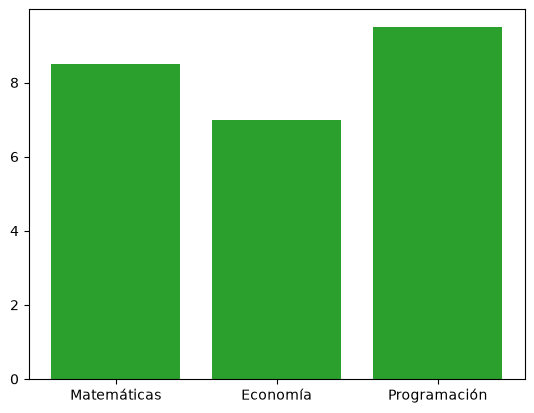

In [2]:
def barras_notas(notas, color):
    fig, ax = plt.subplots()
    ax.bar(list(notas), list(notas.values()), color=color)
    return fig

barras_notas({"Matemáticas": 8.5, "Economía": 7, "Programación": 9.5}, "tab:green")
plt.show()

## 3. Diagrama de cajas

Función que reciba una serie de notas y devuelva un diagrama de cajas titulado *Distribución de notas*.

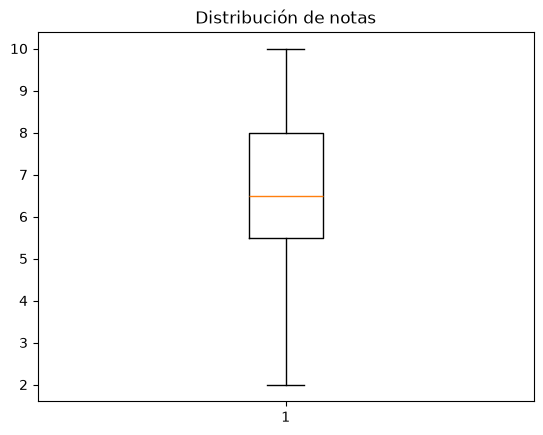

In [3]:
def cajas(notas):
    fig, ax = plt.subplots()
    ax.boxplot(notas)
    ax.set_title("Distribución de notas")
    return fig

cajas(pd.Series([5.5, 8, 7.5, 3, 9, 6.5, 2, 10, 6]))
plt.show()

## 4. Sectores guardados en PNG

Función que reciba una serie con las ventas de los meses de un trimestre y un título, cree un diagrama de sectores y lo guarde en un fichero PNG con ese título.

True


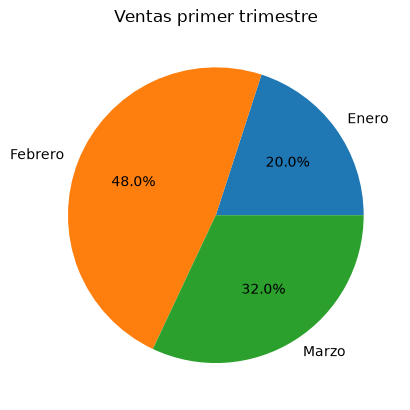

In [4]:
def sectores_png(ventas, titulo):
    fig, ax = plt.subplots()
    ax.pie(ventas, labels=ventas.index, autopct="%1.1f%%")
    ax.set_title(titulo)
    fig.savefig(f"{titulo}.png")
    return fig

fig = sectores_png(pd.Series([500, 1200, 800], index=["Enero", "Febrero", "Marzo"]), "Ventas primer trimestre")
import os
print(os.path.exists("Ventas primer trimestre.png"))
plt.show()

## 5. Tipo de gráfico a elegir

Función que reciba una serie de ventas por años y el tipo de gráfico (`lineas`, `barras`, `sectores` o `areas`) y devuelva un diagrama titulado *Evolución del número de ventas*.

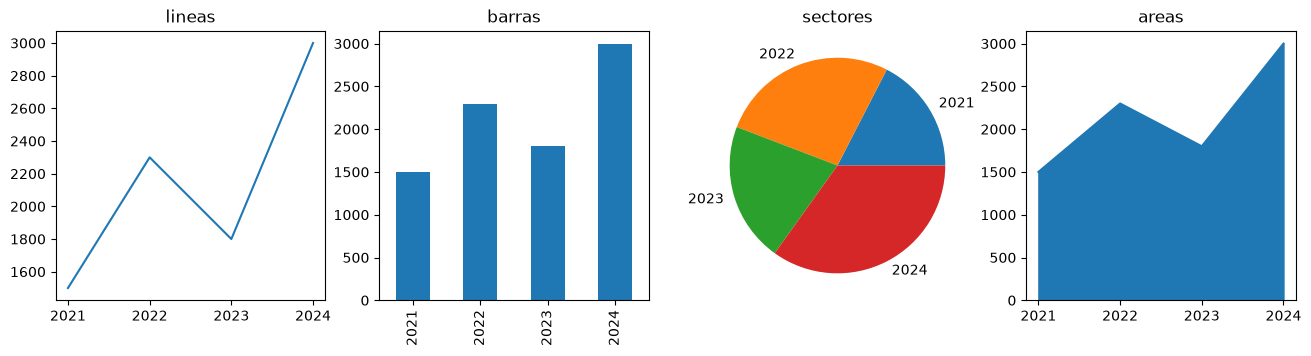

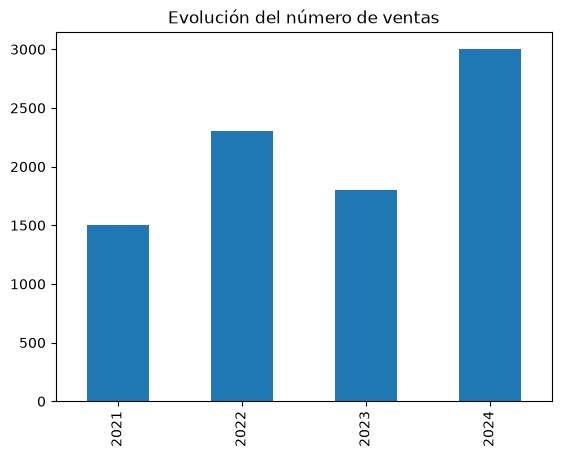

In [5]:
def grafico_ventas(ventas, tipo):
    tipos = {"lineas": "line", "barras": "bar", "sectores": "pie", "areas": "area"}
    ax = ventas.plot(kind=tipos[tipo], title="Evolución del número de ventas")
    return ax.figure

ventas = pd.Series([1500, 2300, 1800, 3000], index=[2021, 2022, 2023, 2024])
fig, ejes = plt.subplots(1, 4, figsize=(16, 3.5))
for eje, tipo in zip(ejes, ("lineas", "barras", "sectores", "areas")):
    plt.sca(eje)
    ventas.plot(kind={"lineas": "line", "barras": "bar", "sectores": "pie", "areas": "area"}[tipo], ax=eje, title=tipo)
plt.show()
grafico_ventas(ventas, "barras")
plt.show()

## 6. Ingresos y gastos

Función que reciba un DataFrame con ingresos y gastos mensuales y devuelva un diagrama con dos líneas, leyenda, el título *Evolución de ingresos y gastos* y el eje $y$ empezando en 0.

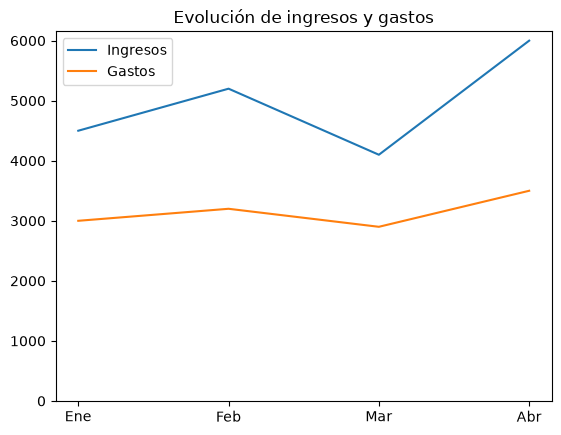

In [6]:
def ingresos_gastos(df):
    fig, ax = plt.subplots()
    ax.plot(df["Mes"], df["Ingresos"], label="Ingresos")
    ax.plot(df["Mes"], df["Gastos"], label="Gastos")
    ax.set_ylim(bottom=0)
    ax.set_title("Evolución de ingresos y gastos")
    ax.legend()
    return fig

ingresos_gastos(pd.DataFrame({"Mes": ["Ene", "Feb", "Mar", "Abr"], "Ingresos": [4500, 5200, 4100, 6000], "Gastos": [3000, 3200, 2900, 3500]}))
plt.show()

## 7. Cotizaciones de bancos

`bancos.csv` contiene las cotizaciones diarias de los principales bancos españoles. Función que reciba el fichero y dibuje la serie temporal de la cotización de cierre de cada banco.

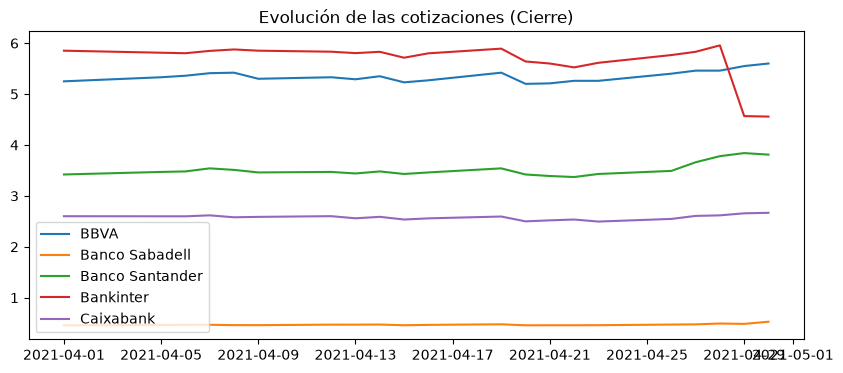

In [7]:
URL_ALF = "https://raw.githubusercontent.com/asalber/aprendeconalf/master/content/es/docencia/python/ejercicios/soluciones/matplotlib/"

def evolucion_cotizacion(fichero, variable="Cierre"):
    datos = pd.read_csv(fichero, parse_dates=["Fecha"])
    fig, ax = plt.subplots(figsize=(10, 4))
    for empresa, grupo in datos.groupby("Empresa"):
        ax.plot(grupo["Fecha"], grupo[variable], label=empresa)
    ax.set_title(f"Evolución de las cotizaciones ({variable})")
    ax.legend()
    return fig

evolucion_cotizacion(URL_ALF + "bancos.csv")
plt.show()

## 8. Gráficos del Titanic

Con `titanic.csv`: sectores con fallecidos y supervivientes, histograma de edades, barras con el número de personas por clase, y barras (separadas y apiladas) de fallecidos y supervivientes por clase.

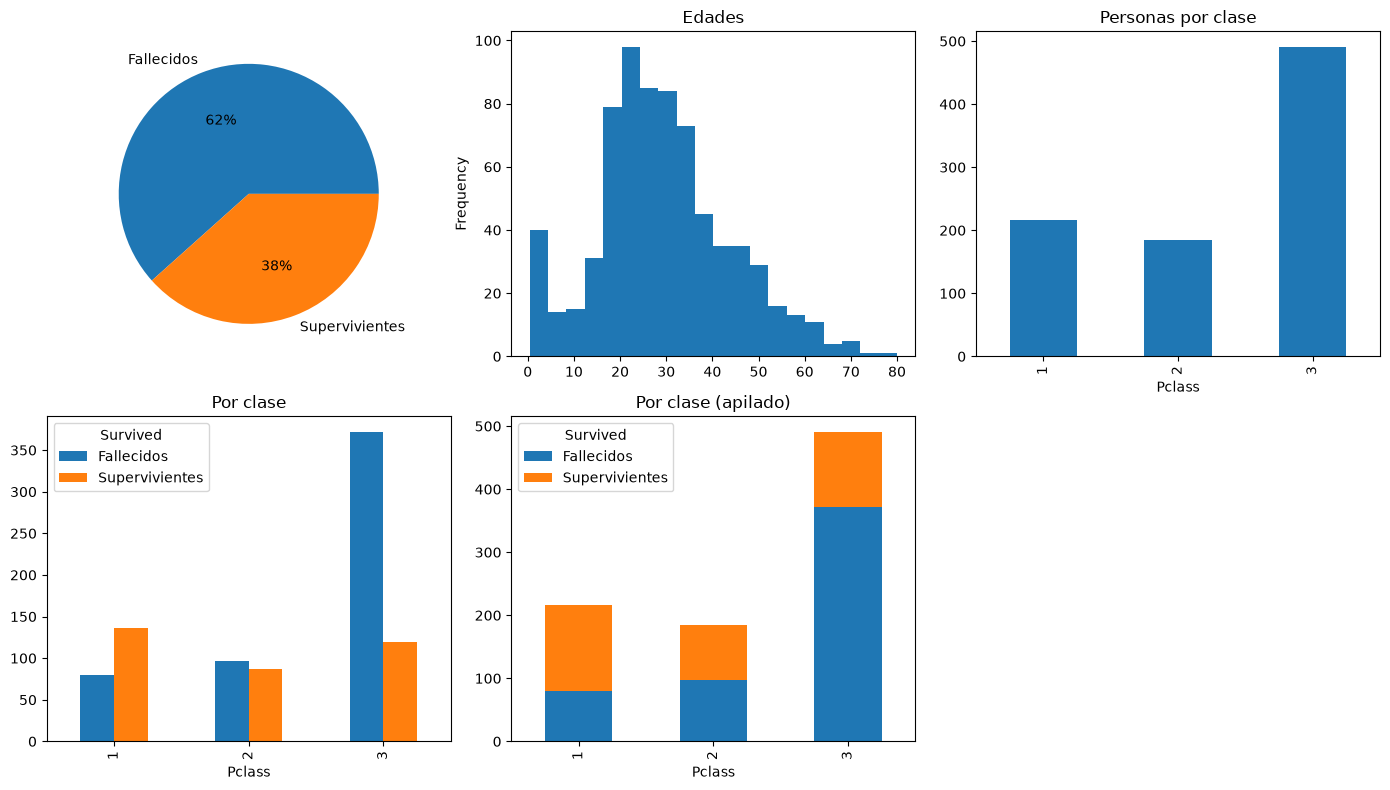

In [8]:
titanic = pd.read_csv(URL_ALF + "titanic.csv")
fig, ejes = plt.subplots(2, 3, figsize=(14, 8))
titanic["Survived"].value_counts().rename({0: "Fallecidos", 1: "Supervivientes"}).plot.pie(ax=ejes[0, 0], autopct="%1.0f%%", ylabel="")
titanic["Age"].plot.hist(ax=ejes[0, 1], bins=20, title="Edades")
titanic["Pclass"].value_counts().sort_index().plot.bar(ax=ejes[0, 2], title="Personas por clase")
por_clase = titanic.groupby(["Pclass", "Survived"]).size().unstack().rename(columns={0: "Fallecidos", 1: "Supervivientes"})
por_clase.plot.bar(ax=ejes[1, 0], title="Por clase")
por_clase.plot.bar(ax=ejes[1, 1], stacked=True, title="Por clase (apilado)")
ejes[1, 2].axis("off")
plt.tight_layout()
plt.show()